# CAT-Net 전체 파인튜닝

    - 작성자: kimjaehak / 작성일: 2026-11-22 / 상태: 작성 중 — 실행 전 준비
    - 실험: `EXP_kimjaehak_006_catnet_finetuning`
    - [실행 안내](../../docs/catnet_training.md) · [개별 보고서](../../docs/catnet/EXP_kimjaehak_006_catnet_finetuning.md)
    - 기준: [004 사전학습 평가](../../docs/catnet/EXP_kimjaehak_004_catnet_pretrained_evaluation.md)

    005는 `last_layer`만, 006은 전체 파라미터를 학습함. 둘 다 동일한 CAT_full_v2에서 독립적으로 시작하며 출력부를 재초기화하지 않음. 파인튜닝도 넓은 의미의 전이학습에 속하지만 이번 비교에서는 학습 범위로 구분함.

    AutoSplice train으로 학습하고 val 손실로 체크포인트를 선택함. AutoSplice test와 CocoGlide는 마지막 평가에만 사용함. 설정은 이 두 실험을 위한 제안값이며 T03·T06 전체의 팀 합의를 뜻하지 않음. 실행 전 두 노트북의 설정을 함께 검토하고 변경 이유를 남겨야 함.

    저장된 출력은 아직 없음. 학습·평가는 사람이 Colab에서 수행함. 003·004와 다른 팀원의 완료 노트북은 수정하지 않음.


## 1. 패키지 설치와 환경 확인

    VS Code의 새 Colab GPU 커널에서 시작함. 아래는 004에서 사용한 추가 의존성 버전이며 torch·torchvision은 런타임 제공 조합을 유지함. 설치 후 재시작 안내가 나오면 커널을 재시작하고 환경 확인 셀부터 진행함. 005·006의 Python·패키지·GPU를 대조해야 하며, 다르면 학습 범위만의 효과라고 해석하지 않음.


In [4]:
%pip install pyjpegio==0.3.0 yacs==0.1.8 torch-dct==0.1.6 PyYAML==6.0.3
%pip install opencv-python==5.0.0.93 tqdm==4.67.3


In [5]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import hashlib
import json
import math
import platform
import random
import sys
import time
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import jpegio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from PIL import Image, features
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

if not torch.cuda.is_available():
    raise RuntimeError("Colab GPU 커널을 연결해야 함.")
if not callable(jpegio.read):
    raise RuntimeError("jpegio.read를 사용할 수 있어야 함.")
packages = ("torch", "torchvision", "numpy", "Pillow", "pandas", "matplotlib", "pyjpegio", "yacs", "PyYAML", "torch-dct", "opencv-python", "tqdm")
environment = {name: version(name) for name in packages}
environment.update(python=platform.python_version(), cuda=str(torch.version.cuda), gpu=torch.cuda.get_device_name(0), jpeg=str(features.version_codec("jpg")))
print("시작 시각 UTC:", datetime.now(timezone.utc).isoformat())
print(json.dumps(environment, ensure_ascii=False, indent=2))
print("GPU 메모리 GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
print("jpegio 경로:", jpegio.__file__)


시작 시각 UTC: 2026-11-22T07:51:08.098920+00:00
{
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "Pillow": "11.3.0",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0",
  "pyjpegio": "0.3.0",
  "yacs": "0.1.8",
  "PyYAML": "6.0.3",
  "torch-dct": "0.1.6",
  "opencv-python": "5.0.0.93",
  "tqdm": "4.67.3",
  "python": "3.13.16",
  "cuda": "13.0",
  "gpu": "NVIDIA A100-SXM4-80GB",
  "jpeg": "6.2"
}
GPU 메모리 GiB: 79.25
jpegio 경로: /usr/local/lib/python3.13/dist-packages/jpegio/__init__.py


## 2. Drive 마운트·경로·공통 코드 확인

    로컬 `scripts/` 전체를 Drive의 `AI_Forensics/project/scripts/`에 업로드해야 함. `__init__.py`와 분할 CSV를 포함함. 최신 main의 전처리는 입력 검사·패딩 함수가 추가되어 004 당시 해시와 다름. 아래 기대값은 이번 준비 시 실제 파일에서 계산한 값임. 불일치하면 업로드 내용과 코드 변경을 확인해야 하며 기대값만 바꾸지 않음.

    체크포인트는 기존 U-Net 동작 확인과 같은 `/content/checkpoints`에 실험 이름으로 임시 저장함. 영구 보관 구조를 정한 것이 아니며, 런타임 종료 전에 다운로드해야 함. 기존 파일이 있으면 덮어쓰기 전에 중단함.


In [6]:
from google.colab import drive

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
code_dir = work_root / "CAT-Net"
weight_source = project_root / "models/pretrained/catnet/CAT_full_v2.pth.tar"
weight_path = work_root / "CAT_full_v2.pth.tar"
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
experiment_id = "EXP_kimjaehak_006_catnet_finetuning"
training_mode = "full"
checkpoint_path = work_root / "checkpoints" / f"{experiment_id}_best.pt"
source_base_commit = "17fa55027c3d331979abf14a2039ad21e017dfb7"
expected_hashes = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/catnet.py": "04d2d6561caf27ae83ccff844adf2b71c02d48470a37359d268f2ee8e217c889",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e"
}

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

for relative, expected in expected_hashes.items():
    path = project_root / relative
    if not path.is_file() or file_sha256(path) != expected:
        raise ValueError(f"공통 파일과 해시를 확인해야 함: {relative}")
    print(relative, expected)

sys.path.insert(0, str(project_root))
from scripts import catnet, datasets, preprocessing, evaluation
for module in (catnet, datasets, preprocessing, evaluation):
    if Path(module.__file__).resolve().parent != (project_root / "scripts").resolve():
        raise RuntimeError("공통 모듈 경로를 확인하고 커널을 재시작해야 함.")
    print("import:", module.__file__)
if checkpoint_path.exists():
    raise FileExistsError("이 실험의 체크포인트가 이미 있음. 이전 결과를 보존하고 새 실험 번호 여부를 확인해야 함.")
print("공통 코드 기준 커밋:", source_base_commit)
print("노트북은 위 커밋 이후 추가한 실행 전 초안이며 공통 코드는 위 해시로 고정함.")
print("체크포인트 임시 경로:", checkpoint_path)


Mounted at /content/drive
scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/catnet.py 04d2d6561caf27ae83ccff844adf2b71c02d48470a37359d268f2ee8e217c889
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
import: /content/drive/MyDrive/AI_Forensics/project/scripts/catnet.py
import: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
import: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
import: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
공통 코드 기준 커밋: 17fa55027c3d331979abf14a2039ad21e017dfb7
노트북은 위 커밋 이후 추가한 실행 전 초안이며 공통 코드는 위 해시로 고정함.
체크포인트 임시 경로: /content/checkpoints/EXP_kimjaehak_00

## 3. 비교 설정

    공통 조건: Adam 1e-4, BCE+Dice 1:1, 배치 2, 최대 20 epoch, val 손실 기준 patience 5, seed 42, FP32임. 두 실험의 차이는 학습 파라미터 범위뿐이며 초기 가중치·배치 순서·크롭 좌표는 맞춤. 실제 조기 종료 epoch과 학습 시간은 달라질 수 있음.

    작은 배치에서 통계가 흔들리지 않도록 두 실험 모두 BatchNorm의 running mean/variance를 고정함. 006에서는 BatchNorm의 affine weight/bias는 학습함. 전이학습은 융합부까지 고정하고 공식 `last_layer` 전체만 학습함. 같은 분할·설정 서명이 나오는지 005·006에서 대조함.

    JPEG 증강·회전·리사이즈·좌우반전은 사용하지 않음. DCT 배열을 픽셀 이미지처럼 뒤집으면 주파수 위치가 바뀌므로 U-Net용 반전을 그대로 적용하지 않음. 학습 크롭의 조작 영역이 비어 있어도 재추출하지 않고 정상 영역 학습에 포함함.


In [7]:
config = {
    "seed": 42,
    "crop_size": 256,
    "crop_grid": 16,
    "batch_size": 2,
    "max_epochs": 20,
    "patience": 5,
    "learning_rate": 1e-4,
    "weight_decay": 0.0,
    "dice_smooth": 1.0,
    "threshold": 0.5,
    "mask_foreground": 255,
    "train_quality": 100,
    "coco_quality": 100,
    "coco_subsampling": 0,
    "bn_running_stats": "frozen",
    "loss": "BCEWithLogits(logit1-logit0) + soft Dice, image mean",
    "selection": "minimum full-resolution val loss, epoch 0 included",
    "augmentation": "aligned random crop only",
    "precision": "float32",
    "deterministic": "warn_only",
}
if config["crop_size"] % config["crop_grid"] or config["crop_grid"] % 8:
    raise ValueError("크롭 크기·좌표는 JPEG 블록 정렬을 유지해야 함.")
protocol = dict(config=config, code_hashes=expected_hashes, official_commit=catnet.CODE_COMMIT, pretrained_sha256=catnet.WEIGHT_SHA256)
protocol_signature = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_all(config["seed"])
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)
print("실험:", experiment_id, "학습 범위:", training_mode)
print(json.dumps(config, ensure_ascii=False, indent=2))
print("005·006 공통 설정 서명:", protocol_signature)
print("CUDA 보간 역전파의 비결정적 연산 경고를 보존함. 시드 고정만으로 비트 단위 재현을 보장하지 않음.")


실험: EXP_kimjaehak_006_catnet_finetuning 학습 범위: full
{
  "seed": 42,
  "crop_size": 256,
  "crop_grid": 16,
  "batch_size": 2,
  "max_epochs": 20,
  "patience": 5,
  "learning_rate": 0.0001,
  "weight_decay": 0.0,
  "dice_smooth": 1.0,
  "threshold": 0.5,
  "mask_foreground": 255,
  "train_quality": 100,
  "coco_quality": 100,
  "coco_subsampling": 0,
  "bn_running_stats": "frozen",
  "loss": "BCEWithLogits(logit1-logit0) + soft Dice, image mean",
  "selection": "minimum full-resolution val loss, epoch 0 included",
  "augmentation": "aligned random crop only",
  "precision": "float32",
  "deterministic": "warn_only"
}
005·006 공통 설정 서명: de71b209c1025273c035762134f7120857e875a2892d7bcbf7fa8318b09b0113
CUDA 보간 역전파의 비결정적 연산 경고를 보존함. 시드 고정만으로 비트 단위 재현을 보장하지 않음.


## 4. AutoSplice train·val 준비

    원본 ID의 고정 CSV를 그대로 사용함. 학습·검증에는 JPEG100 조작본과 정상 원본을 포함하고 각 파일을 한 epoch에 한 번씩 사용함. 정상 원본을 다시 JPEG100으로 저장하지 않음. 정상·조작의 저장 이력 차이가 학습 단서가 될 수 있다는 한계는 보고서에 남김.

    이 단계에서는 test와 CocoGlide를 추론하지 않음. train·val 원본 ID 중복, 파일 종류, 이미지·마스크 크기와 전경값을 확인함. 공통 함수의 ZIP 완료 표시가 있어도 압축 해제 파일을 직접 수정한 이력이 있다면 원본 ZIP으로 새 런타임을 준비해야 함.


In [8]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
datasets.prepare_dataset_zip(shared_root / "datasets/AutoSplice/AutoSplice.zip", work_root / "AutoSplice.zip", data_root, archive_hashes["AutoSplice"])
records = datasets.autosplice_records(data_root / "AutoSplice", split_path, quality=config["train_quality"])
train_records = [r for r in records if r["split"] == "train"]
val_records = [r for r in records if r["split"] == "val"]
split_ids = {split: {r["original_id"] for r in records if r["split"] == split} for split in ("train", "val", "test")}
if any(split_ids[a] & split_ids[b] for a, b in (("train", "val"), ("train", "test"), ("val", "test"))):
    raise ValueError("분할 사이에 같은 원본 ID가 없어야 함.")
if [len(split_ids[s]) for s in ("train", "val", "test")] != [1818, 227, 228]:
    raise ValueError("고정 분할의 원본 ID 수와 일치해야 함.")

def read_mask(record):
    with Image.open(record["image_path"]) as image:
        width, height = image.size
    if record["kind"] == "normal":
        return np.zeros((height, width), dtype=np.uint8)
    if record["kind"] != "manipulated":
        raise ValueError("정상·조작 구분을 확인해야 함.")
    mask = preprocessing.load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
    if mask.shape != (height, width) or not mask.any():
        raise ValueError(f"조작 마스크의 크기와 전경을 확인해야 함: {record['image_path'].name}")
    return mask

for subset in (train_records, val_records):
    if {r["kind"] for r in subset} != {"normal", "manipulated"}:
        raise ValueError("각 분할에 정상·조작 이미지가 모두 있어야 함.")
    if len({r["image_path"] for r in subset}) != len(subset):
        raise ValueError("같은 이미지 경로가 중복되지 않아야 함.")
    for record in tqdm(subset, desc=f"{subset[0]['split']} 무결성 확인"):
        with Image.open(record["image_path"]) as image:
            if image.format != "JPEG":
                raise ValueError("AutoSplice 입력은 원본 JPEG여야 함.")
        mask = read_mask(record)
        if record["split"] == "train" and min(mask.shape) < config["crop_size"]:
            raise ValueError("학습 이미지에서 패딩 없이 설정한 크롭을 만들 수 있어야 함.")

display(pd.DataFrame(train_records + val_records).groupby(["split", "kind"]).size().rename("images").reset_index())
print("원본 ID 수:", {s: len(ids) for s, ids in split_ids.items()})


AutoSplice ZIP SHA-256 확인 및 압축 해제 완료


train 무결성 확인:   0%|          | 0/4743 [00:00<?, ?it/s]

val 무결성 확인:   0%|          | 0/588 [00:00<?, ?it/s]

,split,kind,images
0,train,manipulated,2925
1,train,normal,1818
2,val,manipulated,361
3,val,normal,227


원본 ID 수: {'train': 1818, 'val': 227, 'test': 228}


## 5. 공식 모델 로드·학습 범위 지정

    `from_pretrained`로 동일한 초기 모델을 로드한 뒤 노트북에서 학습 범위를 설정함. `predict_proba`는 추론 전용이므로 학습에는 사용하지 않고 `detector.model(x, qtable)`을 직접 호출함. 006이 005의 학습 가중치에서 이어서 시작하는 방식은 아님.


In [9]:
code_dir = catnet.prepare_code(code_dir)
weight_path = catnet.prepare_weights(weight_source, weight_path)
detector = catnet.CatNetDetector.from_pretrained(code_dir, weight_path, device="cuda")
model, device = detector.model, detector.device
if not isinstance(model.last_layer, nn.Sequential):
    raise TypeError("공식 CAT-Net의 last_layer 구조를 확인해야 함.")
for name, parameter in model.named_parameters():
    parameter.requires_grad_(training_mode == "full" or name.startswith("last_layer."))
trainable_names = {name for name, p in model.named_parameters() if p.requires_grad}
if training_mode not in ("head_only", "full") or not trainable_names:
    raise ValueError("학습 범위와 파라미터를 확인해야 함.")

def set_train_mode():
    model.train()
    if training_mode == "head_only":
        model.eval()
        model.last_layer.train()
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()

print(json.dumps(detector.info, ensure_ascii=False, indent=2))
print(model.last_layer)
print("학습 파라미터:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("고정 파라미터:", sum(p.numel() for p in model.parameters() if not p.requires_grad))
print("학습 파라미터 이름:", sorted(trainable_names))


공식 코드: /content/CAT-Net
코드 커밋: 5eb85900b0e72423c95a8d41bc835b86c8671f8a
가중치 복사·해시 확인 완료: /content/CAT_full_v2.pth.tar
{
  "code_commit": "5eb85900b0e72423c95a8d41bc835b86c8671f8a",
  "code_dir": "/content/CAT-Net",
  "weight_path": "/content/CAT_full_v2.pth.tar",
  "weight_sha256": "f82aaafdd1142775231feedcea0bb7027f7370561d9e8d107465454001865989",
  "weight_bytes": 915503873,
  "epoch": 196,
  "parameters": 114263810,
  "device": "cuda",
  "wrapper_sha256": "04d2d6561caf27ae83ccff844adf2b71c02d48470a37359d268f2ee8e217c889",
  "resize": "bilinear",
  "align_corners": false
}
Sequential(
  (0): Conv2d(360, 360, kernel_size=(1, 1), stride=(1, 1))
  (1): BatchNorm2d(360, eps=1e-05, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Conv2d(360, 2, kernel_size=(1, 1), stride=(1, 1))
)
학습 파라미터: 114263810
고정 파라미터: 0
학습 파라미터 이름: ['bn1.bias', 'bn1.weight', 'bn2.bias', 'bn2.weight', 'conv1.weight', 'conv2.weight', 'dc_layer0_dil.0.bias', 'dc_layer0_

## 6. Dataset·크롭과 입력 시각 확인

    `prepare_input`으로 JPEG 전체의 RGB+DCT 24채널과 양자화 테이블을 읽은 뒤, 원본 안에서 동일한 위치의 입력·마스크를 자름. 시작 좌표를 16의 배수로 고르면 8×8 DCT 블록 내부의 주파수 위치가 유지됨. JPEG를 크롭 파일로 재저장하지 않음.

    크롭 난수는 seed·epoch·목록 index로 별도 계산함. 모델이 사용하는 난수와 분리되어 두 실험에 동일한 좌표가 적용됨. 원본 밖 패딩은 학습 크롭에 들어가지 않음. val·test는 전체 크기로 평가하고 공식 패딩만 제거함.


/content/CAT-Net/Splicing/data/AbstractDataset.py:163: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  t_DCT_coef = torch.tensor(DCT_coef, dtype=torch.float)  # final (but used below)


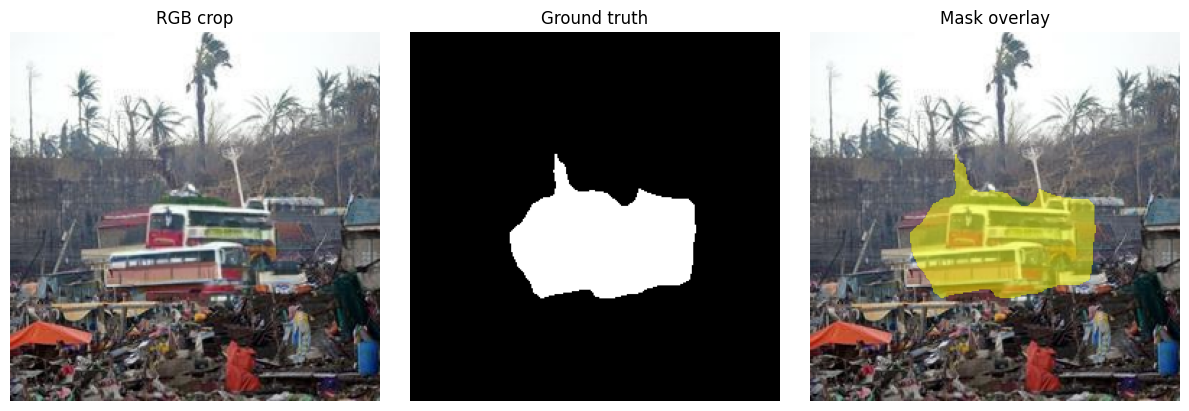

표본: 39406_0.jpg
입력·양자화 테이블·마스크: (24, 256, 256) (1, 8, 8) (256, 256)
마스크 값: [0.0, 1.0] 조작 비율: 0.1239166259765625


In [10]:
def crop_origin(height, width, size, grid, seed, epoch, index):
    if min(height, width) < size or size % grid or grid % 8:
        raise ValueError("크롭 크기와 블록 정렬을 확인해야 함.")
    rng = random.Random(f"{seed}:{epoch}:{index}")
    return rng.randrange((height - size) // grid + 1) * grid, rng.randrange((width - size) // grid + 1) * grid

class AutoSpliceTrainDataset(Dataset):
    def __init__(self, records):
        self.records = records
        self.epoch = 0

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        tensor, qtable, (height, width) = catnet.prepare_input(record["image_path"], code_dir)
        mask = read_mask(record)
        size, grid = config["crop_size"], config["crop_grid"]
        top, left = crop_origin(height, width, size, grid, config["seed"], self.epoch, index)
        x = tensor[:, top:top+size, left:left+size].contiguous()
        y = torch.from_numpy(mask[top:top+size, left:left+size].copy()).float()
        if x.shape != (24, size, size) or qtable.shape != (1, 8, 8):
            raise ValueError("RGB+DCT 입력과 양자화 테이블 크기를 확인해야 함.")
        return x, qtable, y

train_dataset = AutoSpliceTrainDataset(train_records)
preview_index = next(i for i, r in enumerate(train_records) if r["kind"] == "manipulated")
x, q, y = train_dataset[preview_index]
rgb_preview = ((x[:3].permute(1, 2, 0).numpy() + 1) * 127.5).clip(0, 255).astype(np.uint8)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
axes[0].imshow(rgb_preview)
axes[0].set_title("RGB crop")
axes[1].imshow(y.numpy(), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground truth")
axes[2].imshow(rgb_preview)
axes[2].imshow(np.ma.masked_where(y.numpy() == 0, y.numpy()), cmap="autumn", alpha=0.5, vmin=0, vmax=1)
axes[2].set_title("Mask overlay")
for ax in axes:
    ax.axis("off")
plt.show()
print("표본:", train_records[preview_index]["image_path"].name)
print("입력·양자화 테이블·마스크:", tuple(x.shape), tuple(q.shape), tuple(y.shape))
print("마스크 값:", torch.unique(y).tolist(), "조작 비율:", y.mean().item())


## 7. 손실·검증 함수와 작은 배치 학습 점검

    CAT-Net은 정상·조작 두 logits를 출력함. `조작 logit - 정상 logit`에 sigmoid를 적용하면 조작 클래스 softmax와 같으므로 이 차이에 BCEWithLogits를 적용함. Dice는 이미지마다 `(2×교집합+1)/(예측합+정답합+1)`로 계산하고 BCE와 1:1로 더함. 빈 마스크도 식에 포함되며 0으로 나누지 않음.

    logits를 입력 크기로 보간한 뒤 원본 영역만 잘라 val 손실·지표를 계산함. 패딩을 정상 픽셀로 집계하지 않음. 다음 점검은 train의 정상·조작 각 한 장에 3 step만 적용함. gradient·가중치 갱신·고정 파라미터와 BatchNorm 통계 보존을 검사한 뒤 **초기 가중치를 복원하고 optimizer를 폐기함**. 성능 측정이나 파인튜닝 결과가 아님.


In [11]:
def binary_logits(x, qtable, original_size=None):
    logits = model(x, qtable)
    if logits.ndim != 4 or logits.shape[1] != 2:
        raise ValueError("모델 출력은 정상·조작 2채널이어야 함.")
    logits = F.interpolate(logits, size=x.shape[-2:], mode="bilinear", align_corners=False)
    binary = logits[:, 1] - logits[:, 0]
    if original_size is not None:
        height, width = original_size
        binary = binary[:, :height, :width]
    return binary

def segmentation_loss(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none").mean(dim=(-2, -1))
    probability = logits.sigmoid()
    intersection = (probability * target).sum(dim=(-2, -1))
    denominator = probability.sum(dim=(-2, -1)) + target.sum(dim=(-2, -1))
    dice = 1 - (2 * intersection + config["dice_smooth"]) / (denominator + config["dice_smooth"])
    return (bce + dice).mean()

def score_image(mask, probability, kind):
    if probability.shape != mask.shape or not np.isfinite(probability).all():
        raise ValueError("예측 크기와 유한한 확률을 확인해야 함.")
    if probability.min() < 0 or probability.max() > 1:
        raise ValueError("조작 확률은 0~1이어야 함.")
    tp, fp, fn, tn = evaluation.confusion_counts(mask, probability >= config["threshold"])
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                f1=evaluation.pixel_f1(tp, fp, fn) if kind == "manipulated" else None,
                iou=evaluation.iou(tp, fp, fn) if kind == "manipulated" else None,
                fpr=evaluation.false_positive_rate(fp, tn) if kind == "normal" else None)

@torch.no_grad()
def validate(records):
    model.eval()
    rows = []
    for record in tqdm(records, desc="AutoSplice val", leave=False):
        x, q, size = catnet.prepare_input(record["image_path"], code_dir)
        mask = read_mask(record)
        logits = binary_logits(x.unsqueeze(0).to(device), q.unsqueeze(0).to(device), size)
        target = torch.from_numpy(mask).float().unsqueeze(0).to(device)
        loss = float(segmentation_loss(logits, target))
        if not math.isfinite(loss):
            raise ValueError("검증 손실은 유한해야 함.")
        probability = logits.sigmoid()[0].cpu().numpy()
        rows.append(dict(loss=loss, **score_image(mask, probability, record["kind"])))
    table = pd.DataFrame(rows)
    return dict(val_loss=float(table.loss.mean()), val_f1=float(table.f1.mean()),
                val_iou=float(table.iou.mean()), val_fpr=float(table.fpr.mean()))


In [12]:
smoke_indices = [next(i for i, r in enumerate(train_records) if r["kind"] == kind) for kind in ("normal", "manipulated")]
smoke_samples = [train_dataset[i] for i in smoke_indices]
smoke_x, smoke_q, smoke_y = [torch.stack(items).to(device) for items in zip(*smoke_samples)]
initial_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
smoke_optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=config["learning_rate"])
smoke_losses = []
gradients = []
try:
    for step in range(3):
        set_train_mode()
        smoke_optimizer.zero_grad(set_to_none=True)
        loss = segmentation_loss(binary_logits(smoke_x, smoke_q), smoke_y)
        if not torch.isfinite(loss):
            raise ValueError("점검 손실은 유한해야 함.")
        loss.backward()
        gradients = [p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
        if not gradients or any(not torch.isfinite(g).all() for g in gradients):
            raise ValueError("학습 gradient가 존재하고 유한해야 함.")
        if not any(torch.count_nonzero(g).item() for g in gradients):
            raise ValueError("0이 아닌 학습 gradient가 있어야 함.")
        smoke_optimizer.step()
        smoke_losses.append(float(loss.detach()))
    changed_frozen = [name for name, value in model.state_dict().items() if name not in trainable_names and not torch.equal(value.cpu(), initial_state[name])]
    if changed_frozen:
        raise ValueError(f"고정 파라미터·BatchNorm 통계가 바뀌지 않아야 함: {changed_frozen[:3]}")
    changed = [name for name, p in model.named_parameters() if p.requires_grad and not torch.equal(p.detach().cpu(), initial_state[name])]
    if not changed or not any(name.startswith("last_layer.") for name in changed):
        raise ValueError("출력부 가중치 갱신을 확인해야 함.")
    if training_mode == "full" and not any(not name.startswith("last_layer.") for name in changed):
        raise ValueError("파인튜닝에서 특징 추출부도 갱신되어야 함.")
    print("동작 점검 손실:", smoke_losses)
    print("갱신된 파라미터 tensor 수:", len(changed))
    print("고정 파라미터·BatchNorm 통계 보존 확인함.")
finally:
    model.load_state_dict(initial_state, strict=True)
    model.zero_grad(set_to_none=True)
    model.eval()
    gradients.clear()
    del initial_state, smoke_optimizer, smoke_x, smoke_q, smoke_y, smoke_samples
    torch.cuda.empty_cache()
seed_all(config["seed"])
print("초기 가중치 복원 완료. 본 학습은 다음 셀에서 시작함.")


/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


동작 점검 손실: [0.6115835309028625, 1.9886776208877563, 1.2007139921188354]
갱신된 파라미터 tensor 수: 1465
고정 파라미터·BatchNorm 통계 보존 확인함.
초기 가중치 복원 완료. 본 학습은 다음 셀에서 시작함.


## 8. 본 학습·validation·체크포인트 선택

    전체 train을 사용하고 epoch마다 크롭 위치와 순서를 바꿈. val은 매번 동일한 전체 이미지로 평가함. val의 이미지별 BCE+Dice 평균이 가장 작은 체크포인트를 선택함. 학습 전 epoch 0도 후보에 포함하므로 개선이 없으면 사전학습 가중치가 선택될 수 있음. 같은 손실이면 먼저 선택한 epoch을 유지함.

    정상 오탐률·조작 F1·IoU도 함께 출력하되 테스트 점수로 체크포인트를 바꾸지 않음. GPU OOM이 나면 자동으로 이미지를 건너뛰거나 배치를 줄이지 않음. 실패 출력을 저장하고, 005·006에 같은 변경을 적용할지 실행 전에 검토해야 함.

    체크포인트에는 최선 state_dict·환경·설정·해시·학습 이력·검증 표본 예측을 저장함. optimizer 재개 기능은 포함하지 않음. 임시 파일 교체 방식으로 최선 파일을 갱신하며 기존 실험 파일이 있으면 학습 시작 전에 중단함.


In [13]:
if checkpoint_path.exists():
    raise FileExistsError("기존 체크포인트가 있으므로 본 학습을 중복 시작하지 않아야 함.")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
seed_all(config["seed"])
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=config["learning_rate"], weight_decay=config["weight_decay"])
reference_record = val_records[0]
history = []

def save_best(epoch, validation):
    reference = detector.predict_proba(reference_record["image_path"])
    payload = dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()},
                   experiment_id=experiment_id, training_mode=training_mode, epoch=epoch, validation=validation,
                   config=config, environment=environment, protocol_signature=protocol_signature,
                   source_base_commit=source_base_commit, code_hashes=expected_hashes,
                   official_commit=catnet.CODE_COMMIT, pretrained_sha256=catnet.WEIGHT_SHA256,
                   history=list(history), reference_name=reference_record["image_path"].name,
                   reference_probability=torch.from_numpy(reference.copy()))
    temporary = checkpoint_path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(checkpoint_path)

torch.cuda.reset_peak_memory_stats()
start_time = time.perf_counter()
baseline_validation = validate(val_records)
history.append(dict(epoch=0, train_loss=None, seconds=time.perf_counter()-start_time, **baseline_validation))
best_loss, best_epoch, stale_epochs = baseline_validation["val_loss"], 0, 0
save_best(0, baseline_validation)
print("학습 전 val:", baseline_validation)

for epoch in range(1, config["max_epochs"] + 1):
    train_dataset.epoch = epoch
    generator = torch.Generator().manual_seed(config["seed"] + epoch)
    loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True, generator=generator,
                        num_workers=0, pin_memory=True, drop_last=False)
    set_train_mode()
    loss_sum, samples_seen = 0.0, 0
    epoch_start = time.perf_counter()
    for x, q, y in tqdm(loader, desc=f"epoch {epoch}/{config['max_epochs']}"):
        x, q, y = x.to(device), q.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = segmentation_loss(binary_logits(x, q), y)
        if not torch.isfinite(loss):
            raise ValueError("학습 손실이 유한해야 함. 실패 출력을 저장해야 함.")
        loss.backward()
        # 상한 제한 없이 gradient norm의 유한성만 확인함.
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], float("inf"), error_if_nonfinite=True)
        optimizer.step()
        loss_sum += float(loss.detach()) * x.shape[0]
        samples_seen += x.shape[0]
    if samples_seen != len(train_records):
        raise ValueError("한 epoch에 모든 학습 이미지를 한 번씩 사용해야 함.")
    validation = validate(val_records)
    row = dict(epoch=epoch, train_loss=loss_sum/samples_seen, seconds=time.perf_counter()-epoch_start, **validation)
    history.append(row)
    if validation["val_loss"] < best_loss:
        best_loss, best_epoch, stale_epochs = validation["val_loss"], epoch, 0
        save_best(epoch, validation)
    else:
        stale_epochs += 1
    print(json.dumps(dict(row, best_epoch=best_epoch, patience_count=stale_epochs), ensure_ascii=False))
    if stale_epochs >= config["patience"]:
        print("val 손실 조기 종료 조건에 도달함.")
        break
training_seconds = time.perf_counter() - start_time
display(pd.DataFrame(history))
print("선택 epoch:", best_epoch, "최소 val 손실:", best_loss)
print("학습·검증·체크포인트 저장 포함 시간 초:", training_seconds)
print("최대 GPU 할당 GiB:", torch.cuda.max_memory_allocated() / 1024**3)


AutoSplice val:   0%|          | 0/588 [00:00<?, ?it/s]

학습 전 val: {'val_loss': 0.780755278179232, 'val_f1': 0.851658905962529, 'val_iou': 0.7745016166947971, 'val_fpr': 0.11891198891085615}


epoch 1/20:   0%|          | 0/2372 [00:00<?, ?it/s]

AutoSplice val:   0%|          | 0/588 [00:00<?, ?it/s]

{"epoch": 1, "train_loss": 22663.437917319494, "seconds": 1288.30169722, "val_loss": 1.3760137632996046, "val_f1": 0.0, "val_iou": 0.0, "val_fpr": 0.0, "best_epoch": 0, "patience_count": 1}


epoch 2/20:   0%|          | 0/2372 [00:00<?, ?it/s]

... (9 outputs left out)

AutoSplice val:   0%|          | 0/588 [00:00<?, ?it/s]

{"epoch": 5, "train_loss": 1.3864180452834196, "seconds": 1286.2749313260001, "val_loss": 1.3807129466614756, "val_f1": 0.0, "val_iou": 0.0, "val_fpr": 0.0, "best_epoch": 0, "patience_count": 5}
val 손실 조기 종료 조건에 도달함.


,epoch,train_loss,seconds,val_loss,val_f1,val_iou,val_fpr
0,0,NaN,106.165954,0.780755,0.851659,0.774502,0.118912
1,1,22663.437917,1288.301697,1.376014,0.000000,0.000000,0.000000
2,2,1.387113,1299.382631,1.377605,0.000000,0.000000,0.000000
3,3,1.386731,1291.645105,1.378916,0.000000,0.000000,0.000000
4,4,1.386575,1288.718246,1.380026,0.000000,0.000000,0.000000
5,5,1.386418,1286.274931,1.380713,0.000000,0.000000,0.000000


선택 epoch: 0 최소 val 손실: 0.780755278179232
학습·검증·체크포인트 저장 포함 시간 초: 6561.419298959
최대 GPU 할당 GiB: 5.838236331939697


## 9. 선택 가중치 재로드·예측 대조

    학습한 파일을 `from_pretrained`에 넣지 않음. 그 함수는 공식 사전학습 파일의 해시를 검사함. 여기서는 이미 만든 동일 구조에 이번 체크포인트의 state_dict를 strict 로드함. 저장 당시 val 표본 확률과 재로드 확률을 대조함. 오차 허용 범위를 넘으면 테스트 전에 원인을 확인함.

    최선 epoch 이후의 학습 이력은 마지막 history 표에 있으므로 반드시 노트북 출력을 저장해야 함. 체크포인트 파일의 history는 선택 epoch까지의 기록임.


In [14]:
del optimizer
model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
if checkpoint["experiment_id"] != experiment_id or checkpoint["protocol_signature"] != protocol_signature:
    raise ValueError("현재 실험의 체크포인트와 설정이 일치해야 함.")
model.load_state_dict(checkpoint["state_dict"], strict=True)
model.eval()
reloaded_probability = detector.predict_proba(reference_record["image_path"])
reference_probability = checkpoint["reference_probability"].numpy()
max_reload_error = float(np.max(np.abs(reloaded_probability - reference_probability)))
if not np.allclose(reloaded_probability, reference_probability, rtol=1e-5, atol=1e-6):
    raise ValueError("저장 전후 예측을 확인해야 함.")
selected_epoch = checkpoint["epoch"]
selected_validation = checkpoint["validation"]
checkpoint_hash = file_sha256(checkpoint_path)
del checkpoint
print("체크포인트:", checkpoint_path)
print("SHA-256:", checkpoint_hash)
print("선택 epoch:", selected_epoch, "val:", selected_validation)
print("재로드 최대 절대 오차:", max_reload_error)
print("테스트 전에 노트북 출력을 저장하고 런타임 종료 전 체크포인트를 다운로드해야 함.")


/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


체크포인트: /content/checkpoints/EXP_kimjaehak_006_catnet_finetuning_best.pt
SHA-256: b378861f61ee856e638c3ead2313c38b9d1aceaf2e3f7a3227b9623b97e14365
선택 epoch: 0 val: {'val_loss': 0.780755278179232, 'val_f1': 0.851658905962529, 'val_iou': 0.7745016166947971, 'val_fpr': 0.11891198891085615}
재로드 최대 절대 오차: 0.0
테스트 전에 노트북 출력을 저장하고 런타임 종료 전 체크포인트를 다운로드해야 함.


## 10. 테스트 목록·CocoGlide JPEG 입력 준비

    여기부터 선택이 끝난 모델만 평가함. 004와 동일하게 AutoSplice test JPEG100·90·75 조작본 및 정상 원본, CocoGlide 전체를 사용함. 정상 AutoSplice는 한 번만 포함함. CocoGlide는 RGB JPEG100·4:4:4로 별도 변환하며 크기·마스크는 유지함. 임계값 0.5와 변환 조건은 결과를 본 뒤 바꾸지 않음.

    005의 테스트 결과를 이유로 006의 사전 설정을 바꾸지 않음. 테스트를 반복해서 보며 설정을 고르는 작업은 이 비교 범위에 포함하지 않음.


In [15]:
datasets.prepare_dataset_zip(shared_root / "datasets/CocoGlide.zip", work_root / "CocoGlide.zip", data_root / "CocoGlide", archive_hashes["CocoGlide"])
eval_records = []
for quality in (100, 90, 75):
    for record in datasets.autosplice_records(data_root / "AutoSplice", split_path, quality=quality):
        if record["split"] != "test" or (record["kind"] == "normal" and quality != 100):
            continue
        variant = "original" if record["kind"] == "normal" else f"JPEG{quality}"
        eval_records.append(dict(record, variant=variant, input_path=record["image_path"], input_conversion="none"))
coco_root = data_root / "CocoGlide"
jpeg_root = work_root / "catnet_inputs" / experiment_id / "CocoGlide_JPEG100_444"
converted_count = 0
for record in tqdm(datasets.cocoglide_records(coco_root), desc="CocoGlide JPEG 변환"):
    source = record["image_path"]
    destination = (jpeg_root / source.relative_to(coco_root)).with_suffix(".jpg")
    destination.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(source) as image:
        if image.format != "PNG":
            raise ValueError("CocoGlide 원본은 PNG여야 함.")
        size = image.size
        image.convert("RGB").save(destination, format="JPEG", quality=config["coco_quality"], subsampling=config["coco_subsampling"])
    with Image.open(destination) as image:
        if image.format != "JPEG" or image.size != size:
            raise ValueError("변환 JPEG의 형식과 크기를 확인해야 함.")
    eval_records.append(dict(record, variant="PNG", input_path=destination, input_conversion="PNG_to_JPEG100_444"))
    converted_count += 1
if converted_count != 1024 or len(eval_records) != 2257:
    raise ValueError("CocoGlide 변환 1,024장·전체 평가 2,257장이어야 함.")
if len({r["image_path"] for r in eval_records}) != len(eval_records):
    raise ValueError("평가 이미지 경로가 중복되지 않아야 함.")
if any(r["original_id"] not in split_ids["test"] for r in eval_records if r["dataset"] == "AutoSplice"):
    raise ValueError("AutoSplice test 원본만 평가해야 함.")
group_columns = ["dataset", "split", "variant", "input_conversion", "kind"]
display(pd.DataFrame(eval_records).groupby(group_columns).size().rename("images").reset_index())
print("CocoGlide 변환 수:", converted_count, "전체 평가 수:", len(eval_records))


CocoGlide ZIP SHA-256 확인 및 압축 해제 완료


CocoGlide JPEG 변환:   0%|          | 0/1024 [00:00<?, ?it/s]

,dataset,split,variant,input_conversion,kind,images
0,AutoSplice,test,JPEG100,none,manipulated,335
1,AutoSplice,test,JPEG75,none,manipulated,335
2,AutoSplice,test,JPEG90,none,manipulated,335
3,AutoSplice,test,original,none,normal,228
4,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512
5,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512


CocoGlide 변환 수: 1024 전체 평가 수: 2257


## 11. 전체 테스트 평가·집계

    조작 이미지는 Pixel F1·IoU, 정상 이미지는 픽셀 오탐률을 구한 뒤 이미지별 평균을 계산함. 다른 종류의 지표가 NaN인 것은 해당 없음임. 정상 픽셀 오탐률은 정상 이미지 오판 비율과 다름. 실패한 이미지를 건너뛰지 않으며 오류 시 완료 개수와 경로를 출력함.

    전체 이미지별 표도 텍스트로 남겨 저장 출력에서 집계를 재검산할 수 있게 함. 별도 지표 JSON·CSV 저장 구조는 추가하지 않음.


In [16]:
evaluation_rows = []
for record in tqdm(eval_records, desc="고정 모델 테스트"):
    try:
        mask = read_mask(record)
        probability = detector.predict_proba(record["input_path"])
        scores = score_image(mask, probability, record["kind"])
        evaluation_rows.append(dict(dataset=record["dataset"], split=record["split"], variant=record["variant"],
                                    input_conversion=record["input_conversion"], kind=record["kind"],
                                    original_id=record["original_id"], filename=record["image_path"].name,
                                    height=mask.shape[0], width=mask.shape[1], threshold=config["threshold"], **scores))
    except Exception:
        print("평가 중단 이미지:", record["image_path"], "완료 수:", len(evaluation_rows))
        raise
if len(evaluation_rows) != 2257:
    raise ValueError("전체 테스트 평가가 완료되어야 함.")
results_df = pd.DataFrame(evaluation_rows)
metrics_summary = results_df.groupby(group_columns).agg(images=("filename", "size"), pixel_f1=("f1", "mean"),
                                                        iou=("iou", "mean"), false_positive_rate=("fpr", "mean")).reset_index()
if metrics_summary.images.sum() != 2257 or len(metrics_summary) != 6:
    raise ValueError("평가 집단 6개와 전체 개수를 확인해야 함.")
with pd.option_context("display.max_columns", None, "display.precision", 6):
    display(metrics_summary)
print("이미지별 지표 전체 — 저장 출력으로 남김.")
print(results_df.to_string(index=False, float_format=lambda value: f"{value:.8f}"))


고정 모델 테스트:   0%|          | 0/2257 [00:00<?, ?it/s]

/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


,dataset,split,variant,input_conversion,kind,images,pixel_f1,iou,false_positive_rate
0,AutoSplice,test,JPEG100,none,manipulated,335,0.881534,0.804299,NaN
1,AutoSplice,test,JPEG75,none,manipulated,335,0.402966,0.320134,NaN
2,AutoSplice,test,JPEG90,none,manipulated,335,0.804909,0.717195,NaN
3,AutoSplice,test,original,none,normal,228,NaN,NaN,0.146547
4,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512,0.363896,0.287980,NaN
5,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512,NaN,NaN,0.166196


이미지별 지표 전체 — 저장 출력으로 남김.
   dataset         split  variant   input_conversion        kind original_id                               filename  height  width  threshold    tp     fp     fn     tn         f1        iou        fpr
AutoSplice          test original               none      normal       39446                              39446.jpg     327    256 0.50000000     0   2660      0  81052        NaN        NaN 0.03177561
AutoSplice          test original               none      normal       39563                              39563.jpg     351    256 0.50000000     0  81353      0   8503        NaN        NaN 0.90537082
AutoSplice          test original               none      normal       39635                              39635.jpg     256    386 0.50000000     0  18631      0  80185        NaN        NaN 0.18854234
AutoSplice          test original               none      normal       39770                              39770.jpg     256    384 0.50000000     0  61758      0  3654

## 12. 표본 시각화·실행 마무리

    점수 순위로 고르지 않고 seed 42로 각 평가 집단에서 최대 2장을 선택함. 원본 RGB·정답·확률·0.5 예측을 출력하며 CocoGlide 왼쪽 RGB는 변환 전 PNG임. 이미지별 저장 점수를 제목에 표시함. 다시 추론한 그림과 최초 평가의 confusion counts가 다르면 중단함.

    실행 후 성공·실패 사례와 정상 오탐을 검토하고 맨 아래 메모를 작성함. 원본 노트북을 출력 포함으로 저장한 뒤 보고서 갱신을 요청함. 재실험은 새 개인 번호로 진행함.


/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


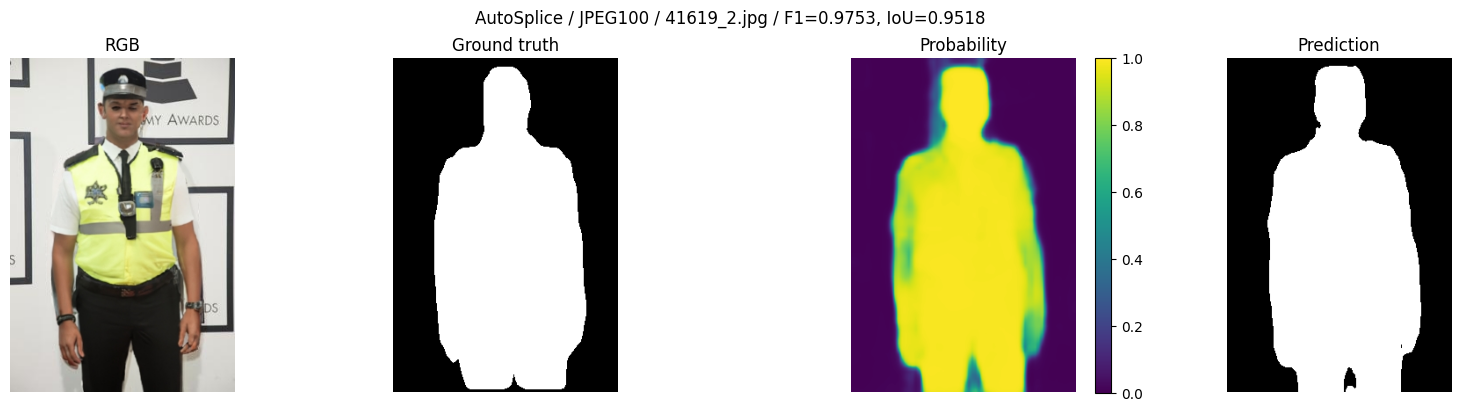

TP·FP·FN·TN: 46352 1563 785 48836


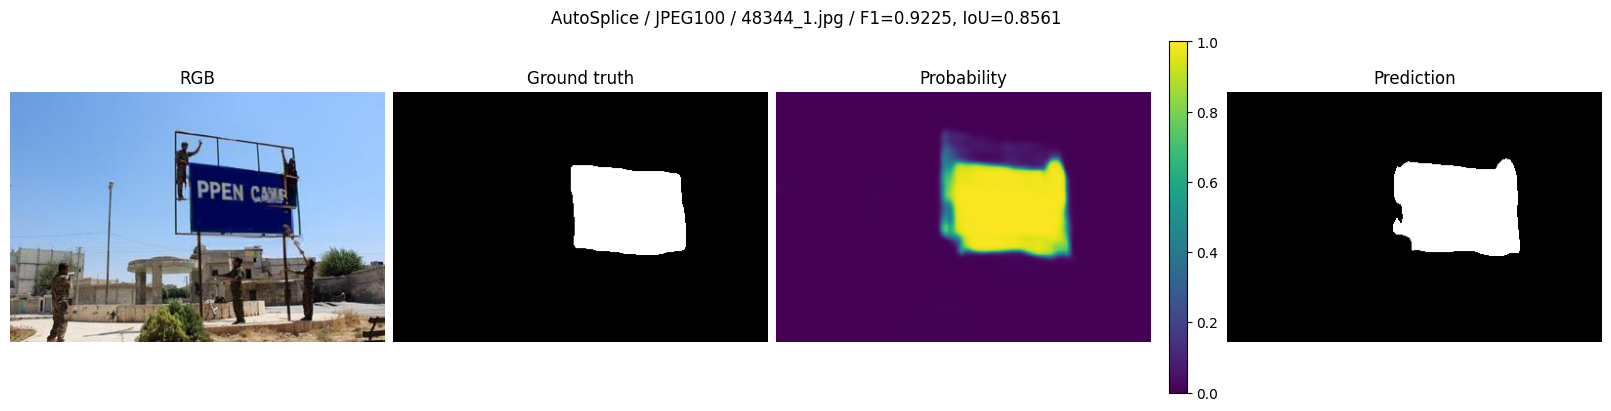

TP·FP·FN·TN: 9474 1430 162 87238


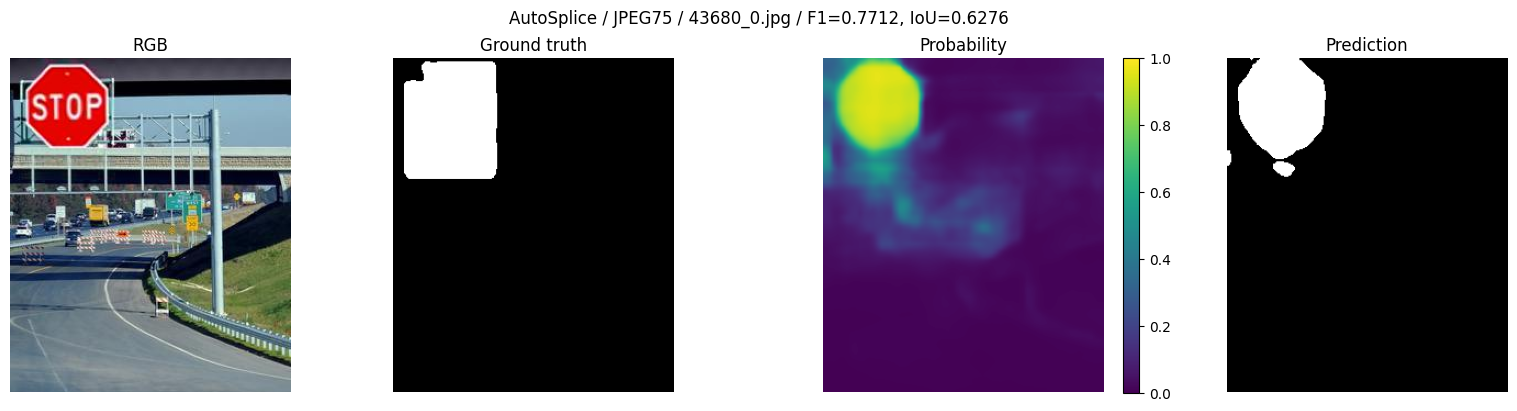

TP·FP·FN·TN: 5670 330 3034 69046


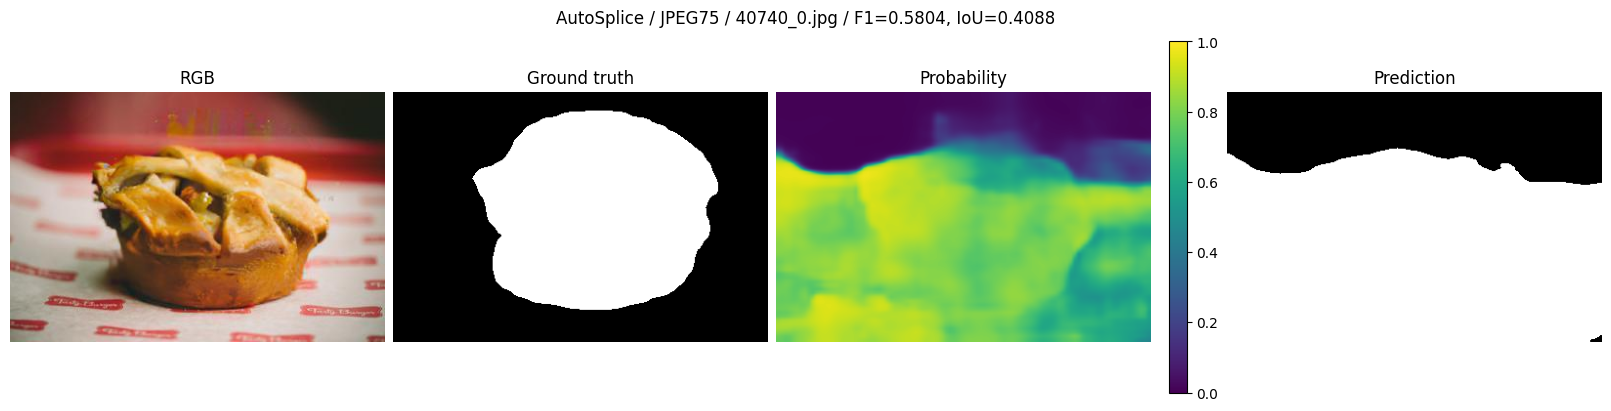

TP·FP·FN·TN: 31499 37717 7830 21258


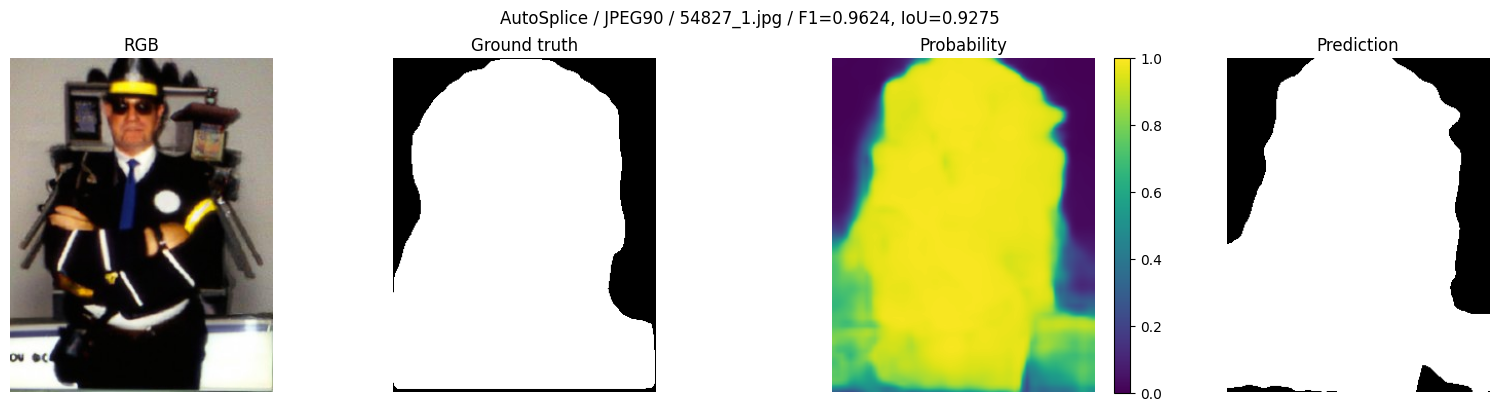

TP·FP·FN·TN: 62865 2523 2389 15679


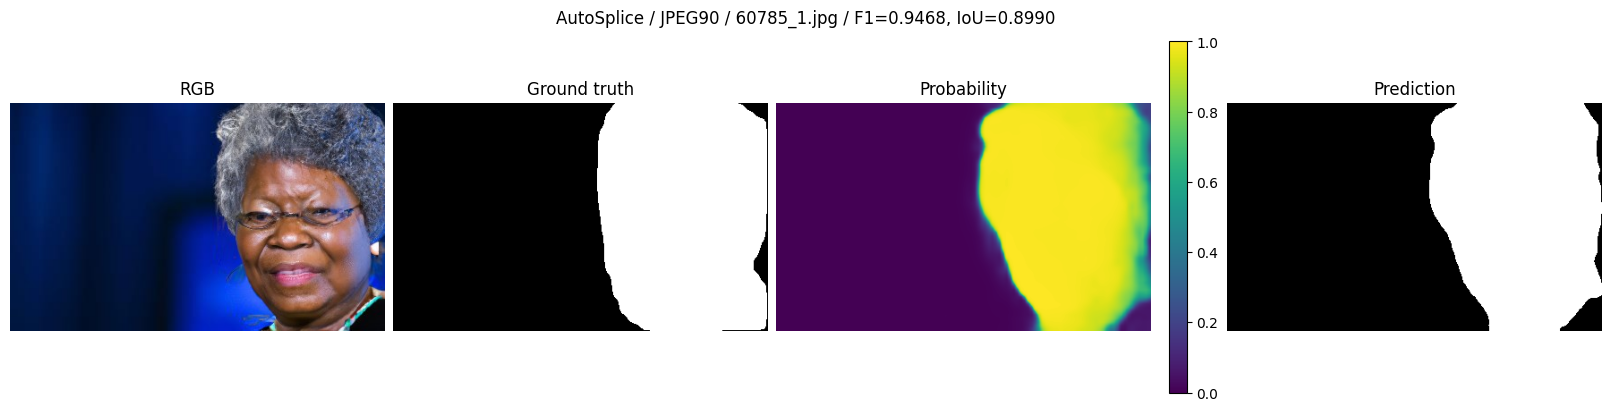

TP·FP·FN·TN: 41095 669 3950 61550


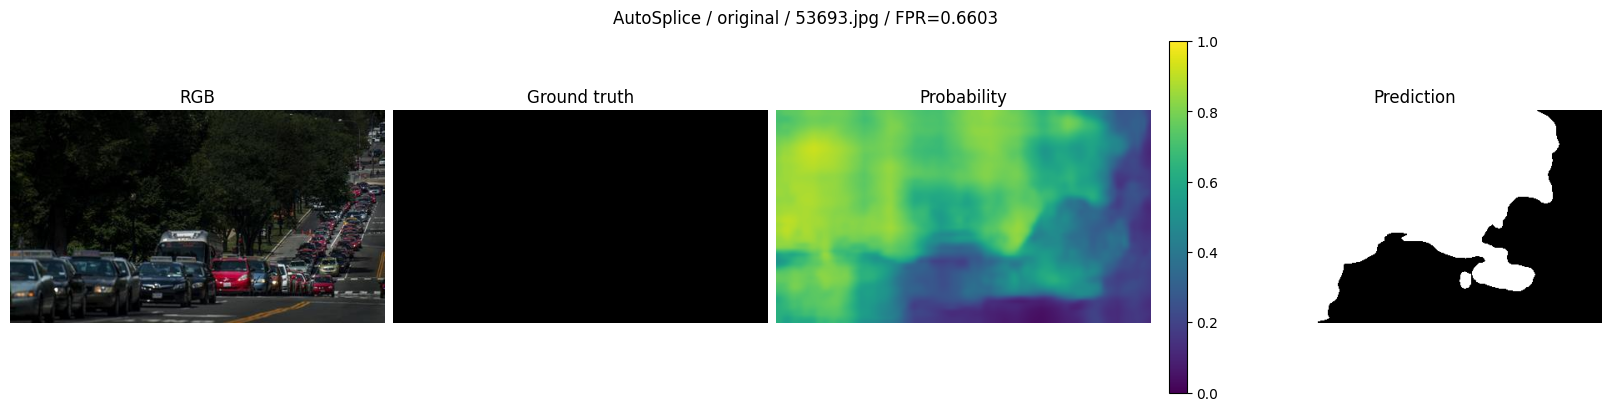

TP·FP·FN·TN: 0 76065 0 39135


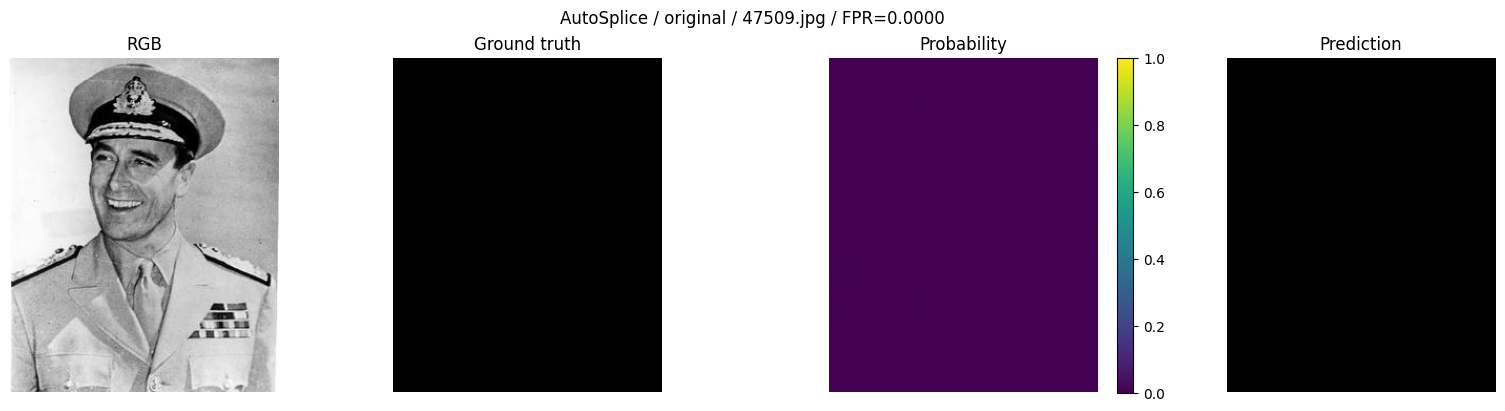

TP·FP·FN·TN: 0 0 0 81664


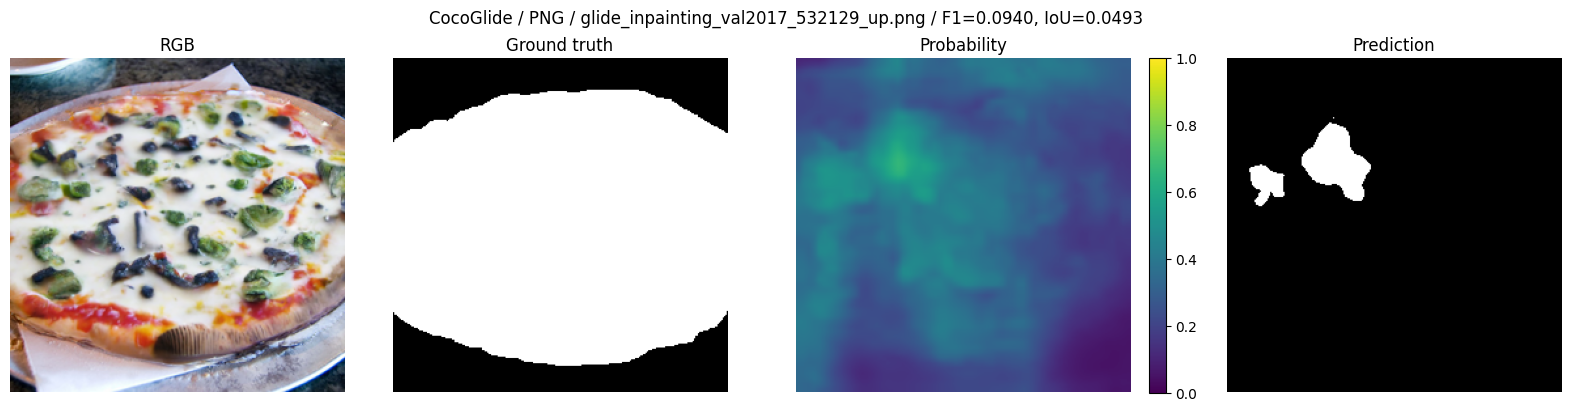

TP·FP·FN·TN: 2353 0 45376 17807


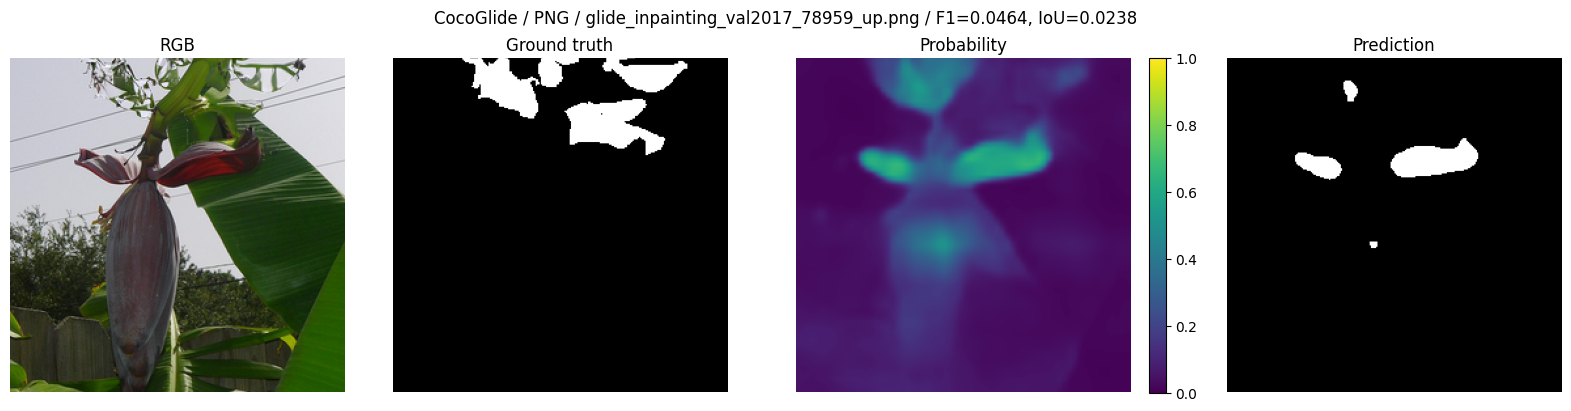

TP·FP·FN·TN: 154 1775 4548 59059


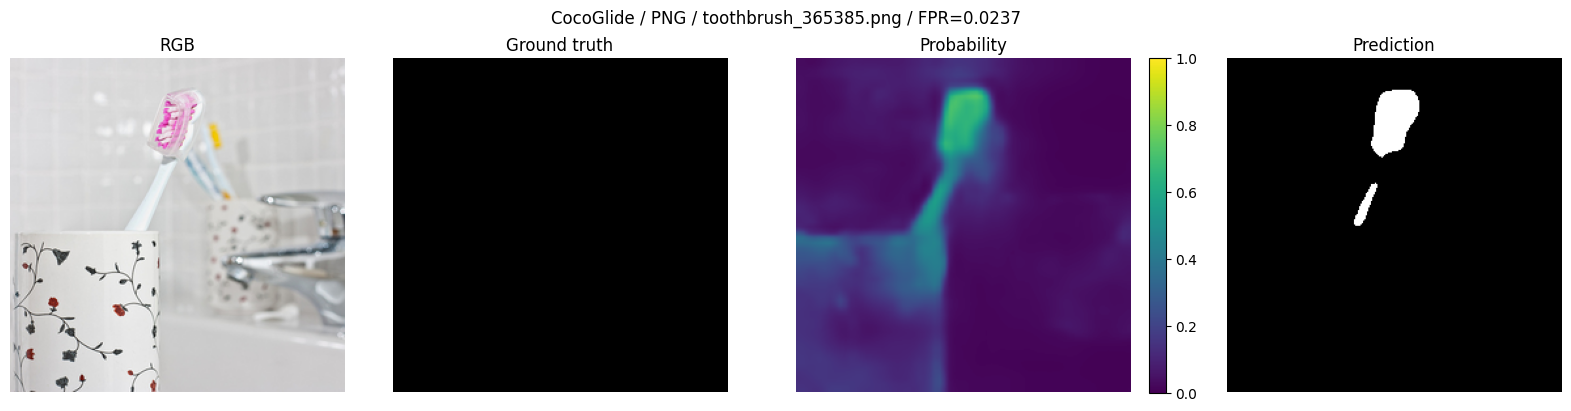

TP·FP·FN·TN: 0 1555 0 63981


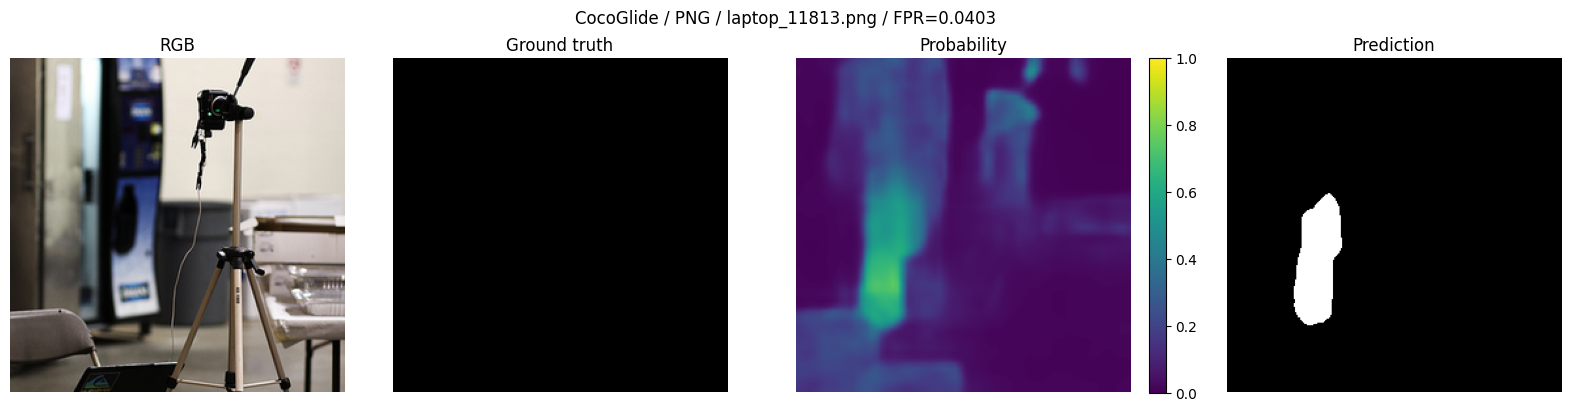

TP·FP·FN·TN: 0 2639 0 62897
실험: EXP_kimjaehak_006_catnet_finetuning 학습 범위: full
선택 epoch: 0 체크포인트 SHA-256: b378861f61ee856e638c3ead2313c38b9d1aceaf2e3f7a3227b9623b97e14365
설정 서명: de71b209c1025273c035762134f7120857e875a2892d7bcbf7fa8318b09b0113
평가 이미지: 2257 그림: 12
완료 시각 UTC: 2026-11-22T09:48:34.910584+00:00
출력과 검토 메모를 저장한 뒤 보고서를 갱신해야 함.


In [17]:
selection = pd.DataFrame(eval_records).groupby(group_columns, group_keys=False).sample(n=2, random_state=42)
for _, record in selection.iterrows():
    mask = read_mask(record)
    probability = detector.predict_proba(record["input_path"])
    prediction = probability >= config["threshold"]
    scores = score_image(mask, probability, record["kind"])
    saved = results_df[(results_df.dataset == record["dataset"]) & (results_df.variant == record["variant"]) &
                       (results_df.kind == record["kind"]) & (results_df.filename == record["image_path"].name)].iloc[0]
    if any(scores[key] != saved[key] for key in ("tp", "fp", "fn", "tn")):
        raise ValueError("시각화와 평가 당시의 예측 개수가 같아야 함.")
    rgb = preprocessing.load_rgb(record["image_path"])
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
    for ax, value, title in zip(axes, (rgb, mask, probability, prediction), ("RGB", "Ground truth", "Probability", "Prediction")):
        plot = ax.imshow(value) if title == "RGB" else ax.imshow(value, cmap="viridis" if title == "Probability" else "gray", vmin=0, vmax=1)
        if title == "Probability":
            fig.colorbar(plot, ax=ax)
        ax.set_title(title)
        ax.axis("off")
    metric_text = f"F1={scores['f1']:.4f}, IoU={scores['iou']:.4f}" if record["kind"] == "manipulated" else f"FPR={scores['fpr']:.4f}"
    fig.suptitle(f"{record['dataset']} / {record['variant']} / {record['image_path'].name} / {metric_text}")
    plt.show()
    print("TP·FP·FN·TN:", scores["tp"], scores["fp"], scores["fn"], scores["tn"])

print("실험:", experiment_id, "학습 범위:", training_mode)
print("선택 epoch:", selected_epoch, "체크포인트 SHA-256:", checkpoint_hash)
print("설정 서명:", protocol_signature)
print("평가 이미지:", len(results_df), "그림:", len(selection))
print("완료 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("출력과 검토 메모를 저장한 뒤 보고서를 갱신해야 함.")


### 체크포인트 다운로드 — 런타임 종료 전

    아래 셀은 런타임의 최선 체크포인트를 다운로드함. 기존 사전학습 파일을 대체하지 않음. `.ipynb` 저장만으로 가중치는 보존되지 않음. 다운로드한 파일의 이름·해시를 실행 기록과 함께 보관해야 함.


In [18]:
from google.colab import files
files.download(str(checkpoint_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 실행자 검토 메모

    - 실제 실행일·실행자: 미기록
    - 설정 변경 여부와 이유: 미기록
    - 005·006 설정 서명·패키지·GPU 대조: 미확인
    - 학습 크롭과 정답 위치 대응: 미확인
    - 선택 epoch·학습 전후 val 변화: 미측정
    - 성공·실패·정상 오탐 사례: 미확인
    - 체크포인트 다운로드·보관: 미확인
    - 오류·경고·중단 여부: 미확인

    첫 셀의 상태와 이 메모는 실행·출력 확인 후 갱신함. 실제 출력이 없는 값을 완료로 기입하지 않음.
